# Hugoniot Fits: Fused Silica


In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-entropy.py # not needed here
%run -i scripts/intersection.py # intersection function
#%run -i scripts/odr_models.py # ODR and model functions not needed here
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'FS-'

In [2]:
## If needed, calculate MC uncertainty envelope for FS Hugoniot liquid
# mc steps= 500, nup samples = 500 are sufficient
## Fused silica PVT Hugoniot
print('Fused silia PTV Hugoniot Monte-Carlo uncertainties')
nsteps = 500
nupind = 500
print('number of up points = ',nupind, ' number of steps = ',nsteps )
dat_mc = hpmc.HPeos_MC()
dat_mc.npts = nsteps

dat_mc.up_ind = np.linspace(fs_fit_liq0.xrange[0],fs_fit_liq0.xrange[1],nupind)
dat_mc.calcMC(fs_fit_liq0 ,fs_fitTus_liq0,verbose=False)

fs_hug_liq.us_std = np.interp(fs_hug_liq.up,dat_mc.up_ind,dat_mc.us_std)
fs_hug_liq.P_std = np.interp(fs_hug_liq.up,dat_mc.up_ind,dat_mc.p_std)
fs_hug_liq.T_std = np.interp(fs_hug_liq.up,dat_mc.up_ind,dat_mc.t_std)
fs_hug_liq.rho_std = np.interp(fs_hug_liq.up,dat_mc.up_ind,dat_mc.rho_std)

dat_mc = [] # free memory

Fused silia PTV Hugoniot Monte-Carlo uncertainties
number of up points =  500  number of steps =  500


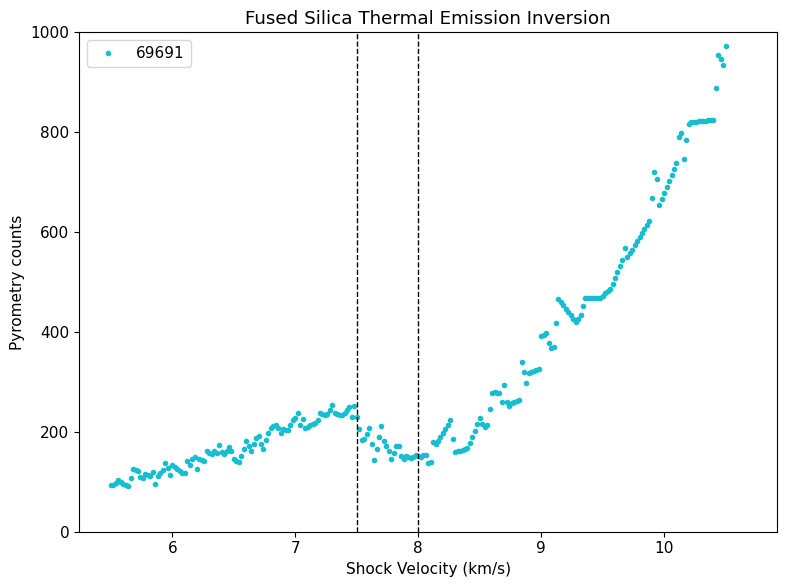

Transition shock velocities:  7.5 8.0
Transition pressures:  65.75879401343992 73.53695488293766


In [3]:
fig, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)

plt.plot(shockdat_list[MDfs69691['id']].us,shockdat_list[MDfs69691['id']].T,'.',label='69691')
# fs_wiggle_us1 and fs_wiggle_us2 are set in define_eos.py
plt.plot([fs_wiggle_us1,fs_wiggle_us1],[0,1000],'k--')
plt.plot([fs_wiggle_us2,fs_wiggle_us2],[0,1000],'k--')
plt.ylim(0,1000)
plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Pyrometry counts')
plt.title('Fused Silica Thermal Emission Inversion')
plt.legend()
plt.tight_layout()
plt.savefig(outputfigpath+tag+'-OmegaFS-Us-counts.pdf')
plt.show()

print('Transition shock velocities: ',fs_wiggle_us1, fs_wiggle_us2)
print('Transition pressures: ',fs_wiggle_P1, fs_wiggle_P2)

## Us-up Fits

Do not include shots 22 or 50 in fits. 

In [4]:
indA23fs = np.arange(0,9) # EOS points with error bars
exclude_shots = ['shot22','shot50']
shotlist = np.asarray(shockdat_list[A23fs['id']].exp_id)
print(shotlist)
indA23fsall = np.asarray([0,1,3,4,5,6,7,8])
indA23fsliq = np.asarray([0,1,3,4,5,8])
print(shotlist[indA23fs])
print(shockdat_list[A23fs['id']].P[indA23fs])
print(shockdat_list[A23fs['id']].us[indA23fs])
print(fs_wiggle_us2)
print(shockdat_list[A23fs['id']].us[indA23fsliq])

['shot20' 'shot21' 'shot22' 'shot23' 'shot25' 'shot31' 'shot40' 'shot41'
 'shot60' 'shot50']
['shot20' 'shot21' 'shot22' 'shot23' 'shot25' 'shot31' 'shot40' 'shot41'
 'shot60']
[ 94.18660988 101.74287646  99.09285427  82.90944976  84.17608215
  83.03434421  56.52890169  54.32443427  87.37011891]
[9.144  9.308  9.163  8.579  8.544  8.569  7.007  6.8343 8.6425]
8.0
[9.144  9.308  8.579  8.544  8.569  8.6425]


Total number of points, other than Z points =  155 30
Number of points in liquid fit =  132
Min max up =  4.755506985737389 18.28
FIT EOS a =  [ 1.11018025e+00  1.71601211e+00 -1.70943423e-02  8.71895791e-05]
FIT EOS cov =  [[ 7.56037741e-02 -2.04326942e-02  1.74996039e-03 -4.77705909e-05]
 [-2.04326942e-02  5.66187766e-03 -4.94281643e-04  1.36944861e-05]
 [ 1.74996039e-03 -4.94281643e-04  4.38216032e-05 -1.22931248e-06]
 [-4.77705909e-05  1.36944861e-05 -1.22931248e-06  3.48489546e-08]]
Quadratic is good for liquid branch.
FIT EOS a =  [ 1.23016646  1.68165661 -0.01401448]
FIT EOS cov =  [[ 1.00927329e-02 -1.65552821e-03  6.46193989e-05]
 [-1.65552821e-03  2.79514285e-04 -1.11638042e-05]
 [ 6.46193989e-05 -1.11638042e-05  4.55338952e-07]]
Saved EOS fit in fs_fit_liq_quadratic.txt
Saved EOS fit in readable file fs_fit_liq_quadratic-readable.txt
rms =  0.07565960017542031
fs_fit_liq check:
Coefficients are the same.
[ 1.23016646  1.68165661 -0.01401448]
[ 1.23016646  1.68165661 -0.01401

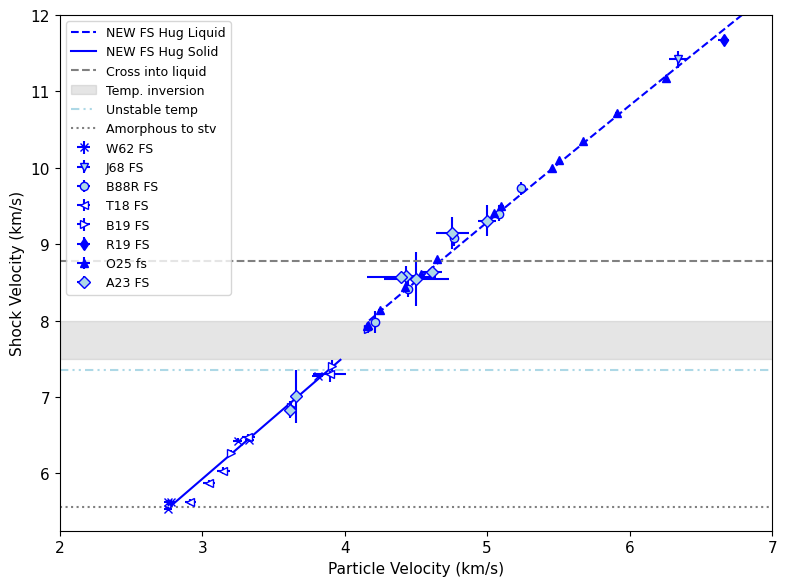

Number of points in liquid fit =  132
Min max up =  4.755506985737389 18.28
FIT EOS a =  [ 1.11018025e+00  1.71601211e+00 -1.70943423e-02  8.71895791e-05]
FIT EOS cov =  [[ 7.56037741e-02 -2.04326942e-02  1.74996039e-03 -4.77705909e-05]
 [-2.04326942e-02  5.66187766e-03 -4.94281643e-04  1.36944861e-05]
 [ 1.74996039e-03 -4.94281643e-04  4.38216032e-05 -1.22931248e-06]
 [-4.77705909e-05  1.36944861e-05 -1.22931248e-06  3.48489546e-08]]
Quadratic is good for liquid branch.
FIT EOS a =  [ 1.23016646  1.68165661 -0.01401448]
FIT EOS cov =  [[ 1.00927329e-02 -1.65552821e-03  6.46193989e-05]
 [-1.65552821e-03  2.79514285e-04 -1.11638042e-05]
 [ 6.46193989e-05 -1.11638042e-05  4.55338952e-07]]
Saved EOS fit in fs_fit_liq_quadratic.txt
Saved EOS fit in readable file fs_fit_liq_quadratic-readable.txt
rms =  0.07565960017542031
fs_fit_liq check:
Coefficients are the same.
[ 1.23016646  1.68165661 -0.01401448]
[ 1.23016646  1.68165661 -0.01401448]


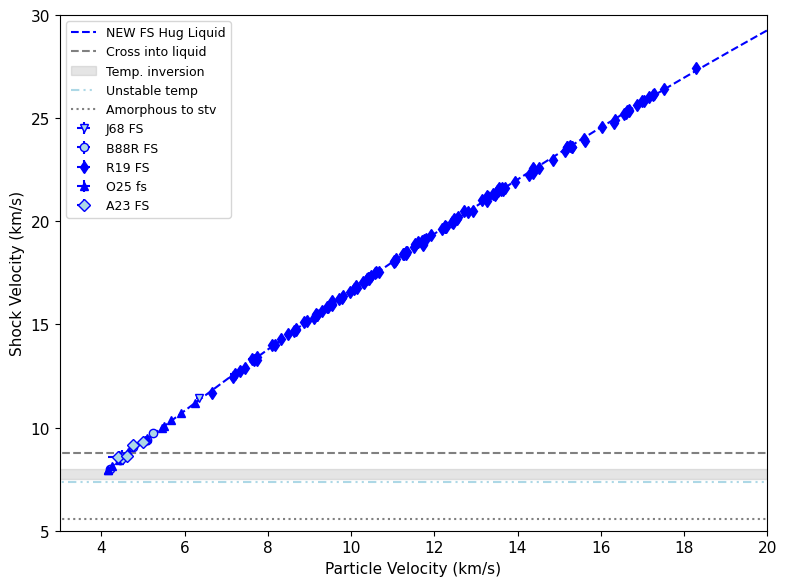

In [5]:
checkpts = False
indB88RRfs = np.arange(0,5) # EOS points with error bars
fsall_up = np.concatenate((shockdat_list[B19fs['id']].up,shockdat_list[A23fs['id']].up[indA23fs],shockdat_list[B88RRfs['id']].up[indB88RRfs],shockdat_list[R19fs['id']].up,shockdat_list[W62fs['id']].up,shockdat_list[T18fs['id']].up[0:5],shockdat_list[J68fs['id']].up))
fsall_us = np.concatenate((shockdat_list[B19fs['id']].us,shockdat_list[A23fs['id']].us[indA23fs],shockdat_list[B88RRfs['id']].us[indB88RRfs],shockdat_list[R19fs['id']].us,shockdat_list[W62fs['id']].us,shockdat_list[T18fs['id']].us[0:5],shockdat_list[J68fs['id']].us))
fsall_up_std = np.concatenate((shockdat_list[B19fs['id']].up_std,shockdat_list[A23fs['id']].up_std[indA23fs],shockdat_list[B88RRfs['id']].up_std[indB88RRfs],shockdat_list[R19fs['id']].up_std,shockdat_list[W62fs['id']].up_std,shockdat_list[T18fs['id']].up_std[0:5],shockdat_list[J68fs['id']].up_std))
fsall_us_std = np.concatenate((shockdat_list[B19fs['id']].us_std,shockdat_list[A23fs['id']].us_std[indA23fs],shockdat_list[B88RRfs['id']].us_std[indB88RRfs],shockdat_list[R19fs['id']].us_std,shockdat_list[W62fs['id']].us_std,shockdat_list[T18fs['id']].us_std[0:5],shockdat_list[J68fs['id']].us_std))
print('Total number of points, other than Z points = ',len(fsall_up),len(fsall_up)-len(shockdat_list[R19fs['id']].up))
# set up the reference arrays
r1 = np.full(len(shockdat_list[B19fs['id']].up), shockdat_list[B19fs['id']].refidlist[1], dtype=int)
r2 = np.full(len(shockdat_list[A23fs['id']].up[indA23fs]), shockdat_list[A23fs['id']].refidlist[1], dtype=int)
r3 = np.full(len(shockdat_list[B88RRfs['id']].up[indB88RRfs]), shockdat_list[B88RRfs['id']].refidlist[1], dtype=int)
r4 = np.full(len(shockdat_list[R19fs['id']].up), shockdat_list[R19fs['id']].refidlist[1], dtype=int)
r5 = np.full(len(shockdat_list[W62fs['id']].up), shockdat_list[W62fs['id']].refidlist[1], dtype=int)
r6 = np.full(len(shockdat_list[T18fs['id']].up[0:5]), shockdat_list[T18fs['id']].refidlist[1], dtype=int)
r7 = np.full(len(shockdat_list[J68fs['id']].up), shockdat_list[J68fs['id']].refidlist[1], dtype=int)
r8 = np.full(len(shockdat_list[O25fs['id']].up), shockdat_list[O25fs['id']].refidlist[1], dtype=int)
fsall_refid = np.concatenate((r1,r2,r3,r4,r5,r6,r7,r8))
fsall_reflist=[]
for i in np.unique(fsall_refid):
    fsall_reflist.append(str(i)+': '+ref_list[i].reference[0])
#print(fsall_reflist)

for ifig in [0,1]:
    
    fig=plt.figure(figsize=fsize)
    
    ind=np.where(fs_hug_liq.us > fs_wiggle_us2 )[0]
    plt.plot(fs_hug_liq.up[ind],fs_hug_liq.us[ind],'b--',label='NEW FS Hug Liquid')
    #plt.plot(fs_hug_R19c.up,fs_hug_R19c.us,'--',color='grey',label='R19 FS Hug Liquid')
    if ifig==0:
#        ind=np.where((fs_hug_tra.us > fs_wiggle_us1) & (fs_hug_tra.us < fs_startliq_us ) )[0]
#        plt.plot(fs_hug_tra.up[ind],fs_hug_tra.us[ind],'b:',linewidth=2,label='NEW FS Hug Transition')
        ind=np.where((fs_hug_stv.us > fs_trans_stv_us) & (fs_hug_stv.us < fs_wiggle_us1 ) )[0]
        plt.plot(fs_hug_stv.up[ind],fs_hug_stv.us[ind],'b-',label='NEW FS Hug Solid')

    if ifig==0:
        plt.errorbar(shockdat_list[W62fs['id']].up,shockdat_list[W62fs['id']].us,fmt='bx',label=W62fs['lab'],\
                     xerr=shockdat_list[W62fs['id']].up_std,yerr=shockdat_list[W62fs['id']].us_std)

    # plot the data; leave off the unused data
    plt.errorbar(shockdat_list[J68fs['id']].up,shockdat_list[J68fs['id']].us,fmt='bv',mfc='lightblue',label=J68fs['lab'],\
                xerr=shockdat_list[J68fs['id']].up_std,yerr=shockdat_list[J68fs['id']].us_std)    
    plt.errorbar(shockdat_list[B88RRfs['id']].up[indB88RRfs],shockdat_list[B88RRfs['id']].us[indB88RRfs],fmt='bo',mfc='lightblue',label=B88RRfs['lab'],\
                 xerr=shockdat_list[B88RRfs['id']].up_std[indB88RRfs],yerr=shockdat_list[B88RRfs['id']].us_std[indB88RRfs])
    if ifig==0:
        plt.errorbar(shockdat_list[T18fs['id']].up,shockdat_list[T18fs['id']].us,fmt='<',color='blue',mfc='white',label=T18fs['lab'],\
                     xerr=shockdat_list[T18fs['id']].up_std,yerr=shockdat_list[T18fs['id']].us_std)
        plt.errorbar(shockdat_list[B19fs['id']].up,shockdat_list[B19fs['id']].us,fmt='b>',mfc='white',label=B19fs['lab'],\
                     xerr=shockdat_list[B19fs['id']].up_std,yerr=shockdat_list[B19fs['id']].us_std)
        
    plt.errorbar(shockdat_list[R19fs['id']].up,shockdat_list[R19fs['id']].us,fmt='bd',\
                 xerr=shockdat_list[R19fs['id']].up_std,yerr=shockdat_list[R19fs['id']].us_std,label=R19fs['lab'])
    plt.errorbar(shockdat_list[O25fs['id']].up,shockdat_list[O25fs['id']].us,fmt='b^',\
                 xerr=shockdat_list[O25fs['id']].up_std,yerr=shockdat_list[O25fs['id']].us_std,label=O25fs['lab'])
    if ifig==0:
        # plot all data
        #indA23fs = np.arange(0,9) # EOS points with error bars
        indA23fs = indA23fsall
        #indA23fs = np.asarray([0])
    else:
        # only plot > thermal inversion data
        #indA23fs = np.asarray([0,1,2,3,4,5,8])
        indA23fs = indA23fsliq
    plt.errorbar(shockdat_list[A23fs['id']].up[indA23fs],shockdat_list[A23fs['id']].us[indA23fs],fmt='bD',mfc='lightblue',\
                 xerr=shockdat_list[A23fs['id']].up_std[indA23fs],yerr=shockdat_list[A23fs['id']].us_std[indA23fs],label=A23fs['lab'])
    
        # problem data
        #plt.errorbar(shockdat_list[L83fshug['id']].up,shockdat_list[L83fshug['id']].us,fmt='o',mec='grey',mfc='grey',label=L83fshug['lab'],\
        #             xerr=shockdat_list[L83fshug['id']].up_std,yerr=shockdat_list[L83fshug['id']].us_std,ecolor='grey')
        #plt.errorbar(fsdf['up'][indfs],fsdf['us'][indfs],fmt='+',color='grey',label='Rusb FS excluded')
        # Jackson something wrong - way too dense states; large errors but still unreasonable
        #plt.errorbar(shockdat_list[J79fs['id']].up,shockdat_list[J79fs['id']].us,fmt='^',mec='grey',mfc='grey',label=J79fs['lab'])
        #plt.errorbar(shockdat_list[J79Rfs['id']].up,shockdat_list[J79Rfs['id']].us,fmt='^',mec='grey',mfc='grey',label=J79Rfs['lab'],\
        #            xerr=shockdat_list[J79Rfs['id']].us_std,yerr=shockdat_list[J79Rfs['id']].us_std,ecolor='grey')

    if 1:
        # plot liquid Hugoniot fit
        indliq = np.where(fsall_us > fs_startliq_us)[0]
        print('Number of points in liquid fit = ',len(indliq))
        print('Min max up = ',min(fsall_up[indliq]),max(fsall_up[indliq]))
        fitx = fsall_up[indliq]
        fitf = fsall_us[indliq]
        fitx_std = fsall_up_std[indliq]
        fitf_std = fsall_us_std[indliq]
        fitrefid = fsall_refid[indliq]
        fitreflist=[]
        for i in np.unique(fitrefid):
            fitreflist.append(str(i)+': '+ref_list[i].reference[0])
        #print(fitreflist)

        if 1:
            # initialize the HPeos_Fit class
            fs_fit_liq = hp.HPeos_Fit()
            fs_fit_liq.matid = 143
            fs_fit_liq.material = 'Quartz amorphous'
            fs_fit_liq.formula = 'SiO2'
            fs_fit_liq.rho_ref = 2.204
            fs_fit_liq.rho_ref_units = 'g/cm³'
            fs_fit_liq.x = fitx
            fs_fit_liq.f = fitf
            fs_fit_liq.x_std = fitx_std
            fs_fit_liq.f_std = fitf_std
            fs_fit_liq.refid = fitrefid
            fs_fit_liq.reflist = fitreflist
            fs_fit_liq.x_var = 'up'
            fs_fit_liq.f_var = 'us'
            fs_fit_liq.x_units = 'km/s'
            fs_fit_liq.f_units = 'km/s'
            fs_fit_liq.x_desc = 'Particle Velocity'
            fs_fit_liq.f_desc = 'Shock Velocity'
            fs_fit_liq.phase_fit = 'liquid'
            fs_fit_liq.remlist.append('Fit to liquid region on the Hugoniot including the metastable extension below the melt curve.')
            fs_fit_liq.remlist.append('Did not include Jackson & Ahrens JGR 1979 (refid=301) because much too dense; there is a problem with this data.')
            fs_fit_liq.remlist.append('Did not include Amodeo thesis points (refid=308) that are based on Hugoniot fits.')
            fs_fit_liq.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
            DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
            fs_fit_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
            fs_fit_liq.curvetype = 'cubic'
            fs_fit_liq.outputfitpath = outputfitpath # in load_paths.py
            fs_fit_liq.filename = 'fs_fit_liq_cubic'
            fs_fit_liq.fit()
            print('FIT EOS a = ',fs_fit_liq.a)
            print('FIT EOS cov = ',fs_fit_liq.cov)
            #fs_fit_liq.savejson()
            #fs_fit_liq.savereadable()
            #print('rms = ',fs_fit_liq.rms)

            nup = np.arange(4,20,.04)
            nus = fs_fit_liq.calcf(nup)
            #plt.plot(nup,nus,'r--',label='cubic')

            print('Quadratic is good for liquid branch.')
            fs_fit_liq.curvetype = 'quadratic'
            fs_fit_liq.outputfitpath = outputfitpath # in load_paths.py
            fs_fit_liq.filename = 'fs_fit_liq_quadratic'
            fs_fit_liq.fit()
            print('FIT EOS a = ',fs_fit_liq.a)
            print('FIT EOS cov = ',fs_fit_liq.cov)
            fs_fit_liq.savejson()
            fs_fit_liq.savereadable()
            print('rms = ',fs_fit_liq.rms)

            print('fs_fit_liq check:')
            fs_fit_liq.comparecoefs(fs_fit_liq0.a)
            if checkpts:
                plt.plot(fitx,fitf,'k+',markersize=20)

            nup = np.arange(4,20,.04)
            nus = fs_fit_liq.calcf(nup)
            #plt.plot(nup,nus,'c--',label='quadratic')
    
    if ifig == 0:
        print('STV FIT TRANSITION May 2025')
        indb = np.where((shockdat_list[W62fs['id']].us > fs_wiggle_us1) & (shockdat_list[W62fs['id']].us < fs_startliq_us))[0]
        indka = np.where((shockdat_list[A23fs['id']].us > fs_wiggle_us1) & (np.asarray(shockdat_list[A23fs['id']].us) < fs_startliq_us) &  (np.asarray(shockdat_list[A23fs['id']].us_std) >0))[0]
  
        fitx = np.concatenate((shockdat_list[B19fs['id']].up[3:4],shockdat_list[A23fs['id']].up[indka],shockdat_list[B88RRfs['id']].up[0:2]))
        fitf = np.concatenate((shockdat_list[B19fs['id']].us[3:4],shockdat_list[A23fs['id']].us[indka],shockdat_list[B88RRfs['id']].us[0:2]))
        fitx_std = np.concatenate((shockdat_list[B19fs['id']].up_std[3:4],shockdat_list[A23fs['id']].up_std[indka],shockdat_list[B88RRfs['id']].up_std[0:2]))
        fitf_std = np.concatenate((shockdat_list[B19fs['id']].us_std[3:4],shockdat_list[A23fs['id']].us_std[indka],shockdat_list[B88RRfs['id']].us_std[0:2]))

        r1 = np.full(len(shockdat_list[B19fs['id']].up[3:4]), shockdat_list[B19fs['id']].refidlist[1], dtype=int)
        r2 = np.full(len(shockdat_list[A23fs['id']].up[indka]), shockdat_list[A23fs['id']].refidlist[1], dtype=int)
        r3 = np.full(len(shockdat_list[B88RRfs['id']].up[0:2]), shockdat_list[B88RRfs['id']].refidlist[1], dtype=int)
        fitrefid = np.concatenate((r1,r2,r3))
        fitreflist=[]
        for i in np.unique(fitrefid):
            fitreflist.append(str(i)+': '+ref_list[i].reference[0])

        print('number of fitted points = ',len(fitx))
        print('min, max up = ',min(fitx),max(fitx))
        if checkpts:
            print(fitx_std/fitx, fitf_std/fitf)
            plt.plot(fitx,fitf,'mo',label='fitted pts',markersize=10)
        if 0:
            print('HPEOS FIT TRANSITION REGION')
            # initialize the HPeos_Fit class
            fs_fit_trans = hp.HPeos_Fit()
            fs_fit_trans.matid = 143
            fs_fit_trans.material = 'Quartz amorphous'
            fs_fit_trans.formula = 'SiO2'
            fs_fit_trans.rho_ref = 2.204
            fs_fit_trans.rho_ref_units = 'g/cm³'
            fs_fit_trans.x = fitx
            fs_fit_trans.f = fitf
            fs_fit_trans.x_std = fitx_std
            fs_fit_trans.f_std = fitf_std
            fs_fit_trans.refid = fitrefid
            fs_fit_trans.reflist = fitreflist
            fs_fit_trans.x_var = 'up'
            fs_fit_trans.f_var = 'us'
            fs_fit_trans.x_units = 'km/s'
            fs_fit_trans.f_units = 'km/s'
            fs_fit_trans.x_desc = 'Particle Velocity'
            fs_fit_trans.f_desc = 'Shock Velocity'
            fs_fit_trans.phase_fit = 'transition from stv to liquid'
            fs_fit_trans.remlist.append('Fit to transition region on the Hugoniot from the onset of optically thick shock front to the melt curve.')
            fs_fit_trans.remlist.append('Did not include Jackson & Ahrens JGR 1979 (refid=301) because much too dense; there is a problem with this data.')
            fs_fit_trans.remlist.append('Did not include Amodeo thesis points (refid=308) that are based on Hugoniot fits.')
            fs_fit_trans.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
            DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
            fs_fit_trans.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
            fs_fit_trans.curvetype = 'linear'
            fs_fit_trans.outputfitpath = outputfitpath # in load_paths.py
            fs_fit_trans.filename = 'fs_fit_trans_linear'
            fs_fit_trans.fit()
            print('FIT EOS a = ',fs_fit_trans.a)
            print('FIT EOS cov = ',fs_fit_trans.cov)
            fs_fit_trans.savejson()
            fs_fit_trans.savereadable()
            print('rms = ',fs_fit_trans.rms)

            print('fs_fit_trans check:')
            fs_fit_trans.comparecoefs(fs_fit_tra0.a)

            nup = np.arange(.8*fs_fit_trans.xrange[0],1.2*fs_fit_trans.xrange[1],.04)
            nus = fs_fit_trans.calcf(nup)
            #plt.plot(nup,nus,'r--',label='trans linear')
            
    if ifig == 0:
        print('STV FIT REDO May 2025')
        indb = np.where((shockdat_list[W62fs['id']].us > fs_trans_stv_us*.9) & (shockdat_list[W62fs['id']].us < fs_wiggle_us1))[0]
        indka = np.where((shockdat_list[A23fs['id']].us > fs_trans_stv_us*1.1) & (np.asarray(shockdat_list[A23fs['id']].us) < fs_wiggle_us1))[0]
        print(indka,shockdat_list[A23fs['id']].us[indka])
        # with JA79
        #fitfsup2 = np.concatenate((shockdat_list[B19fs['id']].up[0:3],shockdat_list[W62fs['id']].up[indb],shockdat_list[T18fs['id']].up[0:5],shockdat_list[J79Rfs['id']].up[0:2],shockdat_list[A23fs['id']].up[6:8]))
        #fitfsus2 = np.concatenate((shockdat_list[B19fs['id']].us[0:3],shockdat_list[W62fs['id']].us[indb],shockdat_list[T18fs['id']].us[0:5],shockdat_list[J79Rfs['id']].us[0:2],shockdat_list[A23fs['id']].us[6:8]))
        #fitfsup2_std = np.concatenate((shockdat_list[B19fs['id']].up_std[0:3],shockdat_list[W62fs['id']].up_std[indb],shockdat_list[T18fs['id']].up_std[0:5],shockdat_list[J79Rfs['id']].up_std[0:2],shockdat_list[A23fs['id']].up_std[6:8]))
        #fitfsus2_std = np.concatenate((shockdat_list[B19fs['id']].us_std[0:3],shockdat_list[W62fs['id']].us_std[indb],shockdat_list[T18fs['id']].us_std[0:5],shockdat_list[J79Rfs['id']].us_std[0:2],shockdat_list[A23fs['id']].us_std[6:8]))
        # without JA79
        fitx = np.concatenate((shockdat_list[B19fs['id']].up[0:3],shockdat_list[W62fs['id']].up[indb],shockdat_list[T18fs['id']].up[0:5],shockdat_list[A23fs['id']].up[indka]))
        fitf = np.concatenate((shockdat_list[B19fs['id']].us[0:3],shockdat_list[W62fs['id']].us[indb],shockdat_list[T18fs['id']].us[0:5],shockdat_list[A23fs['id']].us[indka]))
        fitx_std = np.concatenate((shockdat_list[B19fs['id']].up_std[0:3],shockdat_list[W62fs['id']].up_std[indb],shockdat_list[T18fs['id']].up_std[0:5],shockdat_list[A23fs['id']].up_std[indka]))
        fitf_std = np.concatenate((shockdat_list[B19fs['id']].us_std[0:3],shockdat_list[W62fs['id']].us_std[indb],shockdat_list[T18fs['id']].us_std[0:5],shockdat_list[A23fs['id']].us_std[indka]))

        r1 = np.full(len(shockdat_list[B19fs['id']].up[0:3]), shockdat_list[B19fs['id']].refidlist[1], dtype=int)
        r2 = np.full(len(shockdat_list[W62fs['id']].up[indb]), shockdat_list[W62fs['id']].refidlist[1], dtype=int)
        r3 = np.full(len(shockdat_list[T18fs['id']].up[0:5]), shockdat_list[T18fs['id']].refidlist[1], dtype=int)
        r4 = np.full(len(shockdat_list[A23fs['id']].up[indka]), shockdat_list[A23fs['id']].refidlist[1], dtype=int)
        fitrefid = np.concatenate((r1,r2,r3,r4))
        fitreflist=[]
        for i in np.unique(fitrefid):
            fitreflist.append(str(i)+': '+ref_list[i].reference[0])

        print('number of fitted points = ',len(fitx),len(fitrefid))
        print('min max up = ',min(fitx),max(fitx))
        if checkpts:
            print(fitx_std/fitx, fitf_std/fitf)
            plt.plot(fitx,fitf,'ro',label='fitted pts',markersize=10)

        if 1:
            print('HPEOS FIT STV REGION')
            # initialize the HPeos_Fit class
            fs_fit_stv = hp.HPeos_Fit()
            fs_fit_stv.matid = 143
            fs_fit_stv.material = 'Quartz amorphous'
            fs_fit_stv.formula = 'SiO2'
            fs_fit_stv.rho_ref = 2.204
            fs_fit_stv.rho_ref_units = 'g/cm³'
            fs_fit_stv.x = fitx
            fs_fit_stv.f = fitf
            fs_fit_stv.x_std = fitx_std
            fs_fit_stv.f_std = fitf_std
            fs_fit_stv.refid = fitrefid
            fs_fit_stv.reflist = fitreflist
            fs_fit_stv.x_var = 'up'
            fs_fit_stv.f_var = 'us'
            fs_fit_stv.x_units = 'km/s'
            fs_fit_stv.f_units = 'km/s'
            fs_fit_stv.x_desc = 'Particle Velocity'
            fs_fit_stv.f_desc = 'Shock Velocity'
            fs_fit_stv.phase_fit = 'stishovite'
            fs_fit_stv.remlist.append('Fit to stishovite region on the Hugoniot up to the onset of optically thick shock front.')
            fs_fit_stv.remlist.append('Did not include Jackson & Ahrens JGR 1979 (refid=301) because much too dense; there is a problem with this data.')
            fs_fit_stv.remlist.append('Did not include Amodeo thesis points (refid=308) that are based on Hugoniot fits.')
            fs_fit_stv.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
            DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
            fs_fit_stv.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
            fs_fit_stv.curvetype = 'linear'
            fs_fit_stv.outputfitpath = outputfitpath # in load_paths.py
            fs_fit_stv.filename = 'fs_fit_stv_linear'
            fs_fit_stv.fit()
            print('FIT EOS a = ',fs_fit_stv.a)
            print('FIT EOS cov = ',fs_fit_stv.cov)
            fs_fit_stv.savejson()
            fs_fit_stv.savereadable()
            print('rms = ',fs_fit_stv.rms)

            print('fs_fit_stv check:')
            fs_fit_stv.comparecoefs(fs_fit_stv0.a)

            #nup = np.arange(.8*fs_fit_stv.xrange[0],1.2*fs_fit_stv.xrange[1],.04)
            #nus = fs_fit_stv.calcf(nup)
            #plt.plot(nup,nus,'r-',label='stv linear')

    # boundaries
    plt.plot([2,20],[fs_startliq_us,fs_startliq_us],'--',color='grey',label='Cross into liquid')
    plt.fill_between([2,20],[fs_wiggle_us1,fs_wiggle_us1],[fs_wiggle_us2,fs_wiggle_us2],color='grey',alpha=0.2, label='Temp. inversion')
    # above 63 GPa and 4800 K McQueen & Fritz report time variable thermal emission in FS
    us_mcqueen = np.interp(63,fs_hug_stv.P,fs_hug_stv.us)
    mcqueen, = plt.plot([2,20],[us_mcqueen,us_mcqueen],'-',color='lightblue',label='Unstable temp')
    mcqueen.set_dashes([4, 2, 1, 2, 1, 2])
    plt.plot([2,20],[fs_trans_stv_us,fs_trans_stv_us],':',color='grey',label='Amorphous to stv')
    
    # labels 
    plt.xlabel('Particle Velocity (km/s)')
    plt.ylabel('Shock Velocity (km/s)')
    plt.legend(loc='upper left',fontsize=lfss)

    if ifig == 0:
        plt.xlim(2,7)
        plt.ylim(5.25,12)
        figname='3A-FS-us-up'

    if ifig == 1:
        plt.xlim(3,20)
        plt.ylim(5,30)
        figname='3B-FS-us-up'
    
    
    plt.tight_layout()
    plt.savefig(outputfigpath+tag+figname+'.pdf')
    plt.show()


In [6]:

# assume 2% errors in Podurets 1981 velocities
cst_us_all1 = [shockdat_list[P81cst['id']].us,shockdat_list[L02cst['id']].us,shockdat_list[F24cst['id']].us]
cst_us_all = np.concatenate([np.atleast_1d(x) for x in cst_us_all1])
cst_us_std_all1 = [shockdat_list[P81cst['id']].us*.02,shockdat_list[L02cst['id']].us_std,shockdat_list[F24cst['id']].us_std]
cst_us_std_all = np.concatenate([np.atleast_1d(x) for x in cst_us_std_all1])

r1 = np.full(len(shockdat_list[P81cst['id']].up), shockdat_list[P81cst['id']].refidlist[1], dtype=int)
r2 = np.full(len(shockdat_list[L02cst['id']].up), shockdat_list[L02cst['id']].refidlist[1], dtype=int)
r3 = np.full(len(shockdat_list[F24cst['id']].up), shockdat_list[F24cst['id']].refidlist[1], dtype=int)

cst_refid_all1 = np.concatenate((r1,r2,r3))
cst_refid_all = np.concatenate([np.atleast_1d(x) for x in cst_refid_all1])

print(len(cst_us_std_all))
print(len(cst_refid_all))


18
18


```{figure} ./figs/dot.png
---
width: 1px
name: fs-us-up
---
Hugoniot fits for fused silica. The thermal inversion region is 65.76 to 73.54 GPa. The light blue-filled circles are the {cite:t}`Lyzenga1983` fused silica Hugoniot points with a recalculated impedance match solution (B88RR FS). The recalculated points are in good agreement with the Z data fit from {cite:t}`Root2019`.
```

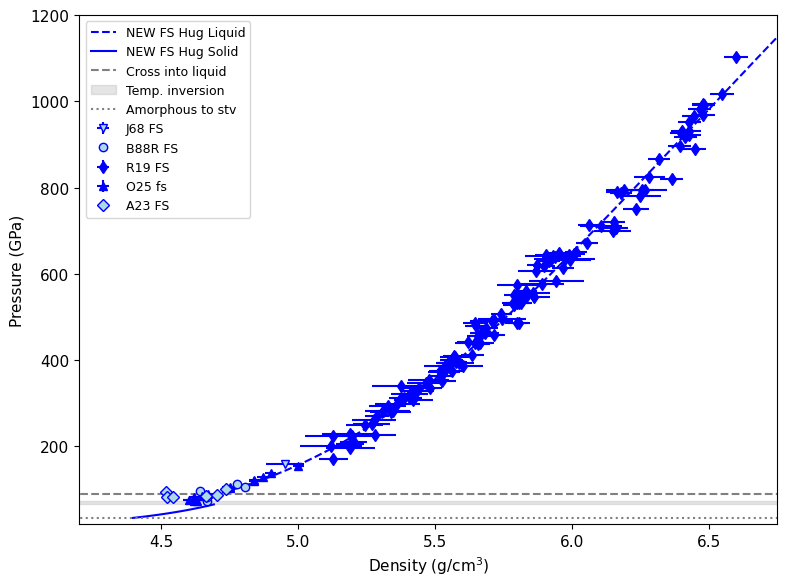

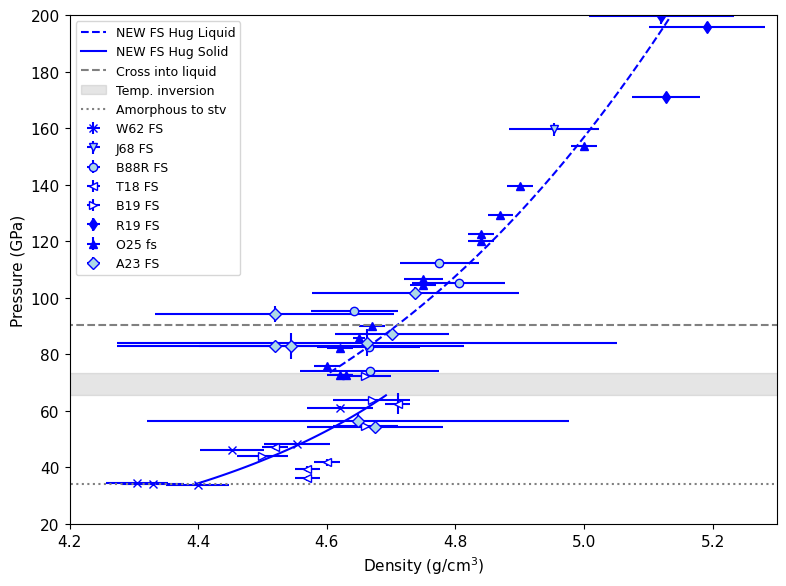

In [7]:
for pind in [1,2]:
    fig=plt.figure(figsize=fsize)

    # plot the Hugoniots
    ind=np.where(fs_hug_liq.us > fs_wiggle_us2 )[0]
    plt.plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b--',label='NEW FS Hug Liquid')
    #plt.plot(fs_hug_R19c.up,fs_hug_R19c.us,'--',color='grey',label='R19 FS Hug Liquid')
    #ind=np.where((fs_hug_tra.us > fs_wiggle_us1) & (fs_hug_tra.us < fs_startliq_us ) )[0]
    #plt.plot(fs_hug_tra.rho[ind],fs_hug_tra.P[ind],'b:',linewidth=2,label='NEW FS Hug Transition')
    ind=np.where((fs_hug_stv.us > fs_trans_stv_us) & (fs_hug_stv.us < fs_wiggle_us1 ) )[0]
    plt.plot(fs_hug_stv.rho[ind],fs_hug_stv.P[ind],'b-',label='NEW FS Hug Solid')

    # plot the data in time order
    # don't plot bad data
    #plt.errorbar(shockdat_list[L83fshug['id']].rho,shockdat_list[L83fshug['id']].P,fmt='o',color='grey',mfc='white',label=L83fshug['lab']+'(excl)')
    #plt.errorbar(shockdat_list[J79fs['id']].rho,shockdat_list[J79fs['id']].P,fmt='r<',mfc='red',label=J79fs['lab'])
    #plt.errorbar(fsdf['rho'][indfs],fsdf['P'][indfs],fmt='+',color='grey',label='Rusb FS excluded')
    if pind == 2:
        plt.errorbar(shockdat_list[W62fs['id']].rho,shockdat_list[W62fs['id']].P,fmt='bx',label=W62fs['lab'],\
                     xerr = shockdat_list[W62fs['id']].rho_std, yerr=shockdat_list[W62fs['id']].P_std )
    plt.errorbar(shockdat_list[J68fs['id']].rho,shockdat_list[J68fs['id']].P,fmt='bv',mfc='lightblue',label=J68fs['lab'],\
                xerr=shockdat_list[J68fs['id']].rho_std,yerr=shockdat_list[J68fs['id']].P_std)
    if pind == 2:
        plt.errorbar(shockdat_list[B88RRfs['id']].rho[indB88RRfs],shockdat_list[B88RRfs['id']].P[indB88RRfs],\
                     xerr=shockdat_list[B88RRfs['id']].rho_std[indB88RRfs],yerr=shockdat_list[B88RRfs['id']].P_std[indB88RRfs],\
                     fmt='bo',mfc='lightblue',label=B88RRfs['lab'])
    else:
        plt.errorbar(shockdat_list[B88RRfs['id']].rho[indB88RRfs],shockdat_list[B88RRfs['id']].P[indB88RRfs],\
                     fmt='bo',mfc='lightblue',label=B88RRfs['lab'])

    if pind == 2:
        plt.errorbar(shockdat_list[T18fs['id']].rho,shockdat_list[T18fs['id']].P,fmt='b<',mfc='white',\
                     xerr=shockdat_list[T18fs['id']].rho_std,yerr=shockdat_list[T18fs['id']].P_std,label=T18fs['lab'])
        plt.errorbar(shockdat_list[B19fs['id']].rho,shockdat_list[B19fs['id']].P,fmt='b>',\
                     xerr=shockdat_list[B19fs['id']].rho_std,\
                     yerr=shockdat_list[B19fs['id']].P_std,mfc='white',label=B19fs['lab'])

    plt.errorbar(shockdat_list[R19fs['id']].rho,shockdat_list[R19fs['id']].P,fmt='bd',\
                 xerr=shockdat_list[R19fs['id']].rho_std,yerr=shockdat_list[R19fs['id']].P_std,label=R19fs['lab'])
    plt.errorbar(shockdat_list[O25fs['id']].rho,shockdat_list[O25fs['id']].P,fmt='b^',\
                 xerr=shockdat_list[O25fs['id']].rho_std,yerr=shockdat_list[O25fs['id']].P_std,label=O25fs['lab'])

    if pind == 2:
        indA23fs = indA23fsall #np.arange(0,9) # EOS points with error bars
        plt.errorbar(shockdat_list[A23fs['id']].rho[indA23fs],shockdat_list[A23fs['id']].P[indA23fs],fmt='bD',mfc='lightblue',label=A23fs['lab'],\
                    xerr=shockdat_list[A23fs['id']].rho_std[indA23fs],yerr=shockdat_list[A23fs['id']].P_std[indA23fs])
    else:
        indA23fs = indA23fsliq #np.asarray([0,1,2,3,4,5,8])
        plt.errorbar(shockdat_list[A23fs['id']].rho[indA23fs],shockdat_list[A23fs['id']].P[indA23fs],fmt='bD',mfc='lightblue',label=A23fs['lab'],\
                    )
    # boundaries
    plt.plot([4,8],[fs_startliq_P,fs_startliq_P],'--',color='grey',label='Cross into liquid')
    plt.fill_between([4,8],[fs_wiggle_P1,fs_wiggle_P1],[fs_wiggle_P2,fs_wiggle_P2],color='grey',alpha=0.2, label='Temp. inversion')
    plt.plot([4,8],[fs_trans_stv_P,fs_trans_stv_P],':',color='grey',label='Amorphous to stv')

    if pind==1:
        plt.ylim(20,1200)
        plt.xlim(4.2,6.75)
        figname='H4b-FS-rho-P'
    if pind==2:
        plt.ylim(20,200)
        plt.xlim(4.2,5.3)
        figname='H4a-FS-rho-P'


    plt.legend(loc='upper left',fontsize=lfss)#, bbox_to_anchor=(1, 0.5))

    plt.xlabel(f'Density (g/cm$^3$)')
    plt.ylabel('Pressure (GPa)')
    #plt.title('Fused silica Hugoniot')

    plt.tight_layout()
    plt.savefig(outputfigpath+figname+'.pdf')
    plt.show()
    #print(shockdat_list[J79fs['id']].P)



```{figure} ./figs/dot.png
---
width: 1px
name: fs-P-rho
---
Hugoniot fits for fused silica. The thermal inversion region is about 65 to 80 GPa. The light blue-filled circles are the {cite:t}`Lyzenga1983` fused silica Hugoniot points with a recalculated impedance match solution (B88R FS). The recalculated points are slightly underdense compared to our fit to the Z data and melt curve tie point.
```

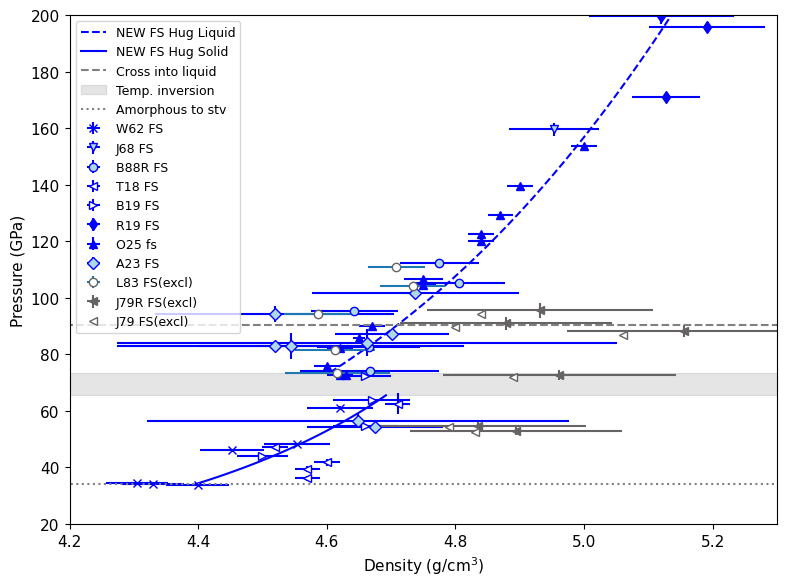

In [9]:
for pind in [2]:
    fig=plt.figure(figsize=fsize)

    # plot the Hugoniots
    ind=np.where(fs_hug_liq.us > fs_wiggle_us2 )[0]
    plt.plot(fs_hug_liq.rho[ind],fs_hug_liq.P[ind],'b--',label='NEW FS Hug Liquid')
    #plt.plot(fs_hug_R19c.up,fs_hug_R19c.us,'--',color='grey',label='R19 FS Hug Liquid')
    #ind=np.where((fs_hug_tra.us > fs_wiggle_us1) & (fs_hug_tra.us < fs_startliq_us ) )[0]
    #plt.plot(fs_hug_tra.rho[ind],fs_hug_tra.P[ind],'b:',linewidth=2,label='NEW FS Hug Transition')
    ind=np.where((fs_hug_stv.us > fs_trans_stv_us) & (fs_hug_stv.us < fs_wiggle_us1 ) )[0]
    plt.plot(fs_hug_stv.rho[ind],fs_hug_stv.P[ind],'b-',label='NEW FS Hug Solid')

    # plot the data in time order
    if pind == 2:
        plt.errorbar(shockdat_list[W62fs['id']].rho,shockdat_list[W62fs['id']].P,fmt='bx',label=W62fs['lab'],\
                     xerr = shockdat_list[W62fs['id']].rho_std, yerr=shockdat_list[W62fs['id']].P_std )
    plt.errorbar(shockdat_list[J68fs['id']].rho,shockdat_list[J68fs['id']].P,fmt='bv',mfc='lightblue',label=J68fs['lab'],\
                xerr=shockdat_list[J68fs['id']].rho_std,yerr=shockdat_list[J68fs['id']].P_std)
    if pind == 2:
        plt.errorbar(shockdat_list[B88RRfs['id']].rho[indB88RRfs],shockdat_list[B88RRfs['id']].P[indB88RRfs],\
                     xerr=shockdat_list[B88RRfs['id']].rho_std[indB88RRfs],yerr=shockdat_list[B88RRfs['id']].P_std[indB88RRfs],\
                     fmt='bo',mfc='lightblue',label=B88RRfs['lab'])
    else:
        plt.errorbar(shockdat_list[B88RRfs['id']].rho[indB88RRfs],shockdat_list[B88RRfs['id']].P[indB88RRfs],\
                     fmt='bo',mfc='lightblue',label=B88RRfs['lab'])

    if pind == 2:
        plt.errorbar(shockdat_list[T18fs['id']].rho,shockdat_list[T18fs['id']].P,fmt='b<',mfc='white',\
                     xerr=shockdat_list[T18fs['id']].rho_std,yerr=shockdat_list[T18fs['id']].P_std,label=T18fs['lab'])
        plt.errorbar(shockdat_list[B19fs['id']].rho,shockdat_list[B19fs['id']].P,fmt='b>',\
                     xerr=shockdat_list[B19fs['id']].rho_std,\
                     yerr=shockdat_list[B19fs['id']].P_std,mfc='white',label=B19fs['lab'])

    plt.errorbar(shockdat_list[R19fs['id']].rho,shockdat_list[R19fs['id']].P,fmt='bd',\
                 xerr=shockdat_list[R19fs['id']].rho_std,yerr=shockdat_list[R19fs['id']].P_std,label=R19fs['lab'])
    plt.errorbar(shockdat_list[O25fs['id']].rho,shockdat_list[O25fs['id']].P,fmt='b^',\
                 xerr=shockdat_list[O25fs['id']].rho_std,yerr=shockdat_list[O25fs['id']].P_std,label=O25fs['lab'])

    if pind == 2:
        indA23fs = indA23fsall# np.arange(0,9) # EOS points with error bars
        plt.errorbar(shockdat_list[A23fs['id']].rho[indA23fs],shockdat_list[A23fs['id']].P[indA23fs],fmt='bD',mfc='lightblue',label=A23fs['lab'],\
                    xerr=shockdat_list[A23fs['id']].rho_std[indA23fs],yerr=shockdat_list[A23fs['id']].P_std[indA23fs])
    else:
        indA23fs = indA23fsliq #np.asarray([0,1,2,3,4,5,8])
        plt.errorbar(shockdat_list[A23fs['id']].rho[indA23fs],shockdat_list[A23fs['id']].P[indA23fs],fmt='bD',mfc='lightblue',label=A23fs['lab'],\
                    )
    # plot the bad data
    bad_col = "#656364" # acc8 dark grey
    
    plt.errorbar(shockdat_list[L83fshug['id']].rho,shockdat_list[L83fshug['id']].P,fmt='o',mfc='white',mec=bad_col,label=L83fshug['lab']+'(excl)',\
                xerr = shockdat_list[L83fshug['id']].rho_std,yerr=shockdat_list[L83fshug['id']].P_std)
    plt.errorbar(shockdat_list[J79Rfs['id']].rho,shockdat_list[J79Rfs['id']].P,fmt='<',mfc=bad_col,mec=bad_col,ecolor=bad_col,label=J79Rfs['lab']+'(excl)',\
                xerr=shockdat_list[J79Rfs['id']].rho_std,yerr=shockdat_list[J79Rfs['id']].P_std)
    plt.errorbar(shockdat_list[J79fs['id']].rho,shockdat_list[J79fs['id']].P,fmt='<',mfc='white',mec=bad_col,label=J79fs['lab']+'(excl)')
                #xerr=shockdat_list[J79fs['id']].rho_std,yerr=shockdat_list[J79fs['id']].P_std)
    #plt.errorbar(fsdf['rho'][indfs],fsdf['P'][indfs],fmt='+',mec=bad_col,label='Rusbank FS (excl)')

    # boundaries
    plt.plot([4,8],[fs_startliq_P,fs_startliq_P],'--',color='grey',label='Cross into liquid')
    plt.fill_between([4,8],[fs_wiggle_P1,fs_wiggle_P1],[fs_wiggle_P2,fs_wiggle_P2],color='grey',alpha=0.2, label='Temp. inversion')
    plt.plot([4,8],[fs_trans_stv_P,fs_trans_stv_P],':',color='grey',label='Amorphous to stv')

    if pind==2:
        plt.ylim(20,200)
        plt.xlim(4.2,5.3)
        figname='H4c-FS-rho-P'


    plt.legend(loc='upper left',fontsize=lfss)#, bbox_to_anchor=(1, 0.5))

    plt.xlabel(f'Density (g/cm$^3$)')
    plt.ylabel('Pressure (GPa)')
    #plt.title('Fused silica Hugoniot')

    plt.tight_layout()
    plt.savefig(outputfigpath+figname+'.pdf')
    plt.show()
    #print(shockdat_list[J79fs['id']].P)



## Temperature Fits


In [10]:
# read in the fused silica decaying shock data from Amodeo et al.
with open('shot50/shot50-analysis.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
    s50time, s50temp, s50temperr, s50pres, s50us, s50up, ind50, isort50,s50tempbackout,Tsteady,Tsteady_err,Psteady,usstart=pickle.load(f)
with open('shot60/shot60-analysis.pkl', 'rb') as f:  # Python 3: open(..., 'wb')
    s60time, s60temp, s60temperr, s60pres, s60us, s60us_err, s60up, ind60, isort60,s60Tsteady,s60Tsteady_err,s60Psteady,s60Psteady_err,s60Ussteady,s60Ussteady_err=pickle.load(f)


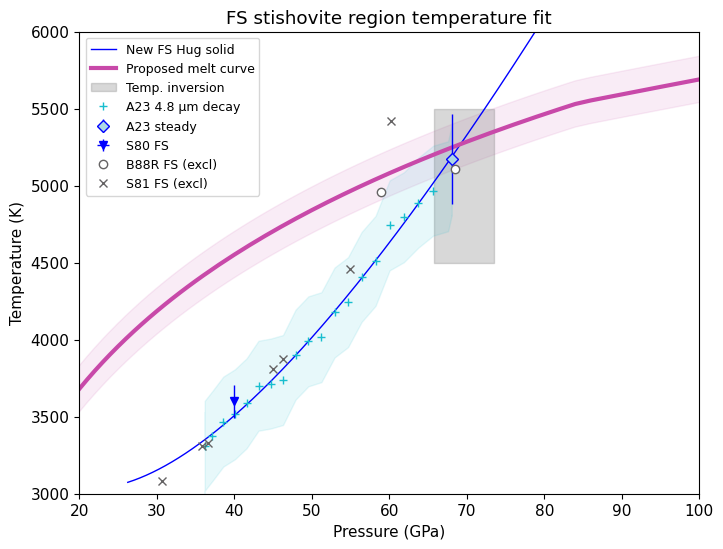

In [11]:
# Decaying shot 50 -- select points for stv region fit
#plt.figure(figsize=fsize)
figure, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)

plt.plot(fs_hug_stv.P,fs_hug_stv.T,'b-',label='New FS Hug solid')

ind = np.where(stsmcsmooth.P <=550)[0]
plt.plot(stsmcsmooth.P[ind],stsmcsmooth.T[ind],'-',color=mc_col,linewidth=3,label='Proposed melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-150,stsmcsmooth.T+150,color=mc_col,alpha=0.1)
plt.fill_between([fs_wiggle_P1,fs_wiggle_P2],[4500,4500],[5500,5500],color='grey',alpha=0.3,label='Temp. inversion')


plt.plot(s50pres[ind50[43:62]],s50tempbackout[ind50[43:62]],'+',color='tab:cyan',label='A23 4.8 μm decay')
#plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='dodgerblue', alpha = 0.1)
plt.fill_between(s50pres[ind50[40::]],s50tempbackout[ind50[40::]]-Tsteady_err,s50tempbackout[ind50[40::]]+Tsteady_err, color='tab:cyan', alpha = 0.1)
plt.errorbar([Psteady],[Tsteady],fmt='bD',mfc='lightblue',label='A23 steady',yerr=[Tsteady_err])

plt.errorbar(shockdat_list[S80fs['id']].P,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].P_std,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab'])
plt.errorbar(shockdat_list[B88RRfs['id']].P[5:7],shockdat_list[B88RRfs['id']].T[5:7],fmt='o',mec=bad_col,mfc='white',label=B88RRfs['lab']+' (excl)')
plt.errorbar(shockdat_list[S81fs['id']].P[0:7],shockdat_list[S81fs['id']].T[0:7],fmt='x',color=bad_col,label=S81fs['lab']+' (excl)')


plt.xlim(20,100)
plt.ylim(3000,6000)
plt.legend(fontsize=lfss)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.title('FS stishovite region temperature fit')
plt.show()


#print(shockdat_list[B88RRfs['id']].us_std)
#print(shockdat_list[B88RRfs['id']].P)
#print(shockdat_list[S81fs['id']].P)


HPEOS T-Us FIT STV REGION
FIT EOS a =  [ 7685.01931198 -2052.47593443   226.34641507]
FIT EOS cov =  [[ 9.48560342e+07 -2.86521077e+07  2.14755660e+06]
 [-2.86521077e+07  8.66498994e+06 -6.50246678e+05]
 [ 2.14755660e+06 -6.50246678e+05  4.88569958e+04]]


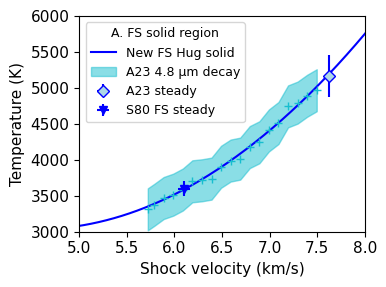

In [12]:
figure, ax = plt.subplots(figsize=fsize1)
#ax.set_prop_cycle(custom_cycler)

plt.plot(fs_hug_stv.us,fs_hug_stv.T,'b-',label='New FS Hug solid')

# Decaying shot 50 -- select points for stv region fit
s50tmp = s50tempbackout[ind50[43:62]]
s50tmp_err = np.zeros(len(s50tmp))+Tsteady_err
s50us_err = np.zeros(len(s50tmp))+.04
#plt.errorbar(s50us[ind50[43:62]]/1.e3,s50tempbackout[ind50[43:62]],yerr=s50tmp_err,xerr=s50us_err,
#             fmt='+',color='tab:cyan',label='A23 4.8 μm decay')
plt.plot(s50us[ind50[43:62]]/1.e3,s50tempbackout[ind50[43:62]],'+',color='tab:cyan')
plt.fill_between(s50us[ind50[43:62]]/1.e3,s50tempbackout[ind50[43:62]]-s50tmp_err,s50tempbackout[ind50[43:62]]+s50tmp_err,color='tab:cyan',alpha=0.5,label='A23 4.8 μm decay')


plt.errorbar([usstart/1.e3],[Tsteady],fmt='bD',mfc='lightblue',label='A23 steady',xerr = [.04],yerr=[Tsteady_err])

plt.errorbar(shockdat_list[S80fs['id']].us,shockdat_list[S80fs['id']].T,fmt='bv',xerr=shockdat_list[S80fs['id']].us*.01,yerr=shockdat_list[S80fs['id']].T_std,label=S80fs['lab']+' steady')
#plt.errorbar(shockdat_list[B88RRfs['id']].us[5:7],shockdat_list[B88RRfs['id']].T[5:7],fmt='o',mec='grey',mfc='white',label=B88RRfs['lab']+' (excl)')
#plt.errorbar(shockdat_list[S81fs['id']].us[0:7],shockdat_list[S81fs['id']].T[0:7],fmt='x',color='grey',label=S81fs['lab']+' (excl)')

fitus = np.concatenate((s50us[ind50[43:62]]/1.e3,[usstart/1.e3],shockdat_list[S80fs['id']].us))
fittemp = np.concatenate((s50tempbackout[ind50[43:62]],[Tsteady],shockdat_list[S80fs['id']].T))
fitus_std = np.concatenate((s50us_err,[.04],shockdat_list[S80fs['id']].us*.01))
fittemp_std = np.concatenate((s50tmp_err,[Tsteady_err],shockdat_list[S80fs['id']].T_std))

r1 = np.full(len(fitus-1), shockdat_list[A23fs['id']].refidlist[1], dtype=int)
r2 = np.full(len(shockdat_list[S80fs['id']].us), shockdat_list[S80fs['id']].refidlist[1], dtype=int)
fitfsrefid2 = np.concatenate((r1,r2))
fitfsreflist2=[]
for i in np.unique(fitfsrefid2):
    fitfsreflist2.append(str(i)+': '+ref_list[i].reference[0])

if 1:
    # use new fitting system
    print('HPEOS T-Us FIT STV REGION')
    # initialize the HPeos_Fit class
    fs_fitTUs_stv = hp.HPeos_Fit()
    fs_fitTUs_stv.matid = 143
    fs_fitTUs_stv.material = 'Quartz amorphous'
    fs_fitTUs_stv.formula = 'SiO2'
    fs_fitTUs_stv.rho_ref = 2.204
    fs_fitTUs_stv.rho_ref_units = 'g/cm³'
    fs_fitTUs_stv.x = fitus
    fs_fitTUs_stv.f = fittemp
    fs_fitTUs_stv.x_std = fitus_std
    fs_fitTUs_stv.f_std = fittemp_std
    fs_fitTUs_stv.refid = fitfsrefid2
    fs_fitTUs_stv.reflist = fitfsreflist2
    fs_fitTUs_stv.x_var = 'us'
    fs_fitTUs_stv.f_var = 'T'
    fs_fitTUs_stv.x_units = 'km/s'
    fs_fitTUs_stv.f_units = 'K'
    fs_fitTUs_stv.x_desc = 'Shock Velocity'
    fs_fitTUs_stv.f_desc = 'Temperature'
    fs_fitTUs_stv.phase_fit = 'stishovite'
    fs_fitTUs_stv.remlist.append('Fit to stishovite region on the Hugoniot up to the onset of optically thick shock front.')
    fs_fitTUs_stv.remlist.append('Based on steady-then-decaying shot50 from Amodeo thesis (refid=308) for 4.8 μm optically thick shock front fit.')
    fs_fitTUs_stv.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    fs_fitTUs_stv.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    fs_fitTUs_stv.curvetype = 'quadratic'
    fs_fitTUs_stv.outputfitpath = outputfitpath # in load_paths.py
    fs_fitTUs_stv.filename = 'fs_fitTUs_stv_quadratic'
    fs_fitTUs_stv.fit()
    print('FIT EOS a = ',fs_fitTUs_stv.a)
    print('FIT EOS cov = ',fs_fitTUs_stv.cov)
    #fs_fitTUs_stv.savejson()
    #fs_fitTUs_stv.savereadable()
    #print('rms = ',fs_fitTUs_stv.rms)

    #print('fs_fitTUs_stv check:')
    #fs_fitTUs_stv.comparecoefs(fs_fitTUs_stv0.a)

    nup = np.arange(.8*fs_fitTUs_stv.xrange[0],1.2*fs_fitTUs_stv.xrange[1],.04)
    nus = fs_fitTUs_stv.calcf(nup)
    #plt.plot(fitus,fittemp,'rX')
    #plt.plot(nup,nus,'r-',label='stv T-Us quadratic')

#plt.errorbar(fitus,fittemp,xerr=fitus_std,yerr=fittemp_std,fmt='+',color='red')
if 0:
    # fit the us-T in this region
    resinit = np.polyfit(fitus,fittemp,1)
    data = RealData(fitus, fittemp, sx=fitus_std, sy=fittemp_std)
    odr = ODR(data, linear_model, beta0=resinit)  # Initial guess: slope=1, intercept=0
    output=odr.run()
    resodr = output.beta
    covodr = output.cov_beta
    print('ODR STV Us-T linear fit = ',resodr)
    print('ODR COV = ',covodr)
    test = (resodr[0]-fsresstv_temp[0])+ (resodr[1]-fsresstv_temp[1] )
    if abs(test) > 1.e-5:
        print(test)
        print('***** WARNING STV Us-T LINEAR FIT DOES NOT MATCH!! ********')
    print('fsresstv_temp = ',fsresstv_temp)



if 0:
    resinit = np.polyfit(fitus,fittemp,2)
    data = RealData(fitus, fittemp, sx=fitus_std, sy=fittemp_std)
    odr = ODR(data, quadratic_model, beta0=resinit)  # Initial guess: slope=1, intercept=0
    output=odr.run()
    resodr = output.beta
    covodr = output.cov_beta
    print('ODR STV Us-T quadratic fit = ',resodr)
    print('ODR COV = ',covodr)
    test = (resodr[0]-fsresstv_temp[0])+ (resodr[1]-fsresstv_temp[1])+ (resodr[2]-fsresstv_temp[2] )
    if abs(test) > 1.e-5:
        print(test)
        print('***** WARNING STV Us-T quadratic FIT DOES NOT MATCH!! ********')
    print('fsresstv_temp = ',fsresstv_temp)



#plt.xlim(20,100)
plt.xlim(5,8)
plt.ylim(3000,6000)
plt.legend(title='A. FS solid region',fontsize=lfss, title_fontsize=lfss)
plt.xlabel('Shock velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.tight_layout()
plt.savefig(outputfigpath+tag+'A-FS-tfit.pdf')
plt.show()

#print(shockdat_list[B88RRfs['id']].us_std)
#print(shockdat_list[B88RRfs['id']].P)
#print(shockdat_list[S81fs['id']].P)


HPEOS T-Us FIT LIQUID REGION
FIT EOS a =  [-1418.43732175   526.81629308   -12.79969681     4.97920132]
FIT EOS cov =  [[ 2.10765070e+07 -5.23860880e+06  4.11776667e+05 -1.02210243e+04]
 [-5.23860880e+06  1.30991231e+06 -1.03651903e+05  2.58919154e+03]
 [ 4.11776667e+05 -1.03651903e+05  8.26453994e+03 -2.07999137e+02]
 [-1.02210243e+04  2.58919154e+03 -2.07999137e+02  5.27646136e+00]]
Saved EOS fit in fs_fitTus_liq_cubic.txt
Saved EOS fit in readable file fs_fitTus_liq_cubic-readable.txt
rms =  250.15529623434017
fs_fitTus_liq check:
Coefficients are the same.
[-1418.43732175   526.81629308   -12.79969681     4.97920132]
[-1418.43732175   526.81629308   -12.79969681     4.97920132]


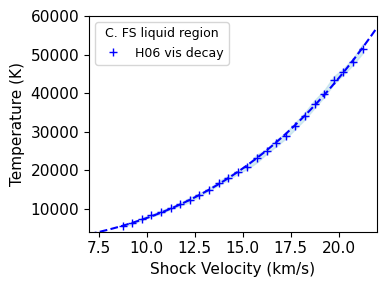

0 H06 vis decay
1 A23 vis decay
2 Trans. to liquid
3 A23 steady
4 B88R FS steady


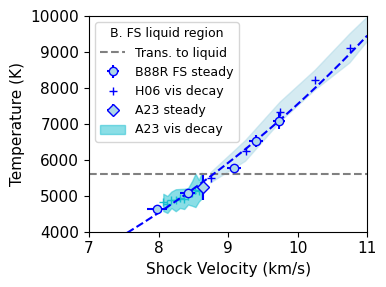

In [13]:
indb = np.arange(5)

#figure, ax = plt.subplots(2,1,figsize=(4,6))
figure, ax = plt.subplots(figsize=fsize1)
plt.rcParams['lines.markersize'] = mks


ind =np.where(shockdat_list[H06fs['id']].T>0)
ax.plot(shockdat_list[H06fs['id']].us[ind],shockdat_list[H06fs['id']].T[ind],'b+',label='H06 vis decay')
ax.fill_between(shockdat_list[H06fs['id']].us[ind],shockdat_list[H06fs['id']].T[ind]-shockdat_list[H06fs['id']].T_std[ind],shockdat_list[H06fs['id']].T[ind]+shockdat_list[H06fs['id']].T_std[ind],color='lightblue',alpha=0.5)
ax.plot(fs_hug_liq.us,fs_hug_liq.T,'b--')

if 1:
    indb = np.arange(5)
    indh =np.where(shockdat_list[H06fs['id']].T>0)[0]
    s60tmp = s60us[ind60[47:59]]/1.e3 # km/s
    s60tmp_std = s60us_err[ind60[47:59]]/1.e3 # km/s error
    #print(s60tmp,s60tmp_std,s60tmp_std/s60tmp)
    usfit = np.concatenate((shockdat_list[B88RRfs['id']].us[indb],shockdat_list[H06fs['id']].us[indh],s60tmp))
    usfit_std = np.concatenate((shockdat_list[B88RRfs['id']].us_std[indb],shockdat_list[H06fs['id']].us_std[indh],s60tmp_std))
    tfit = np.concatenate((shockdat_list[B88RRfs['id']].T[indb],shockdat_list[H06fs['id']].T[indh],s60temp[ind60[47:59]]))
    tfit_std = np.concatenate((shockdat_list[B88RRfs['id']].T_std[indb],shockdat_list[H06fs['id']].T_std[indh],s60temperr[ind60[47:59]]))

    r1 = np.full(len(indb), shockdat_list[B88RRfs['id']].refidlist[1], dtype=int)
    r2 = np.full(len(indh), shockdat_list[H06fs['id']].refidlist[1], dtype=int)
    r3 = np.full(len(s60tmp), shockdat_list[A23fs['id']].refidlist[1], dtype=int)
    fitfsrefid2 = np.concatenate((r1,r2,r3))
    fitfsreflist2=[]
    for i in np.unique(fitfsrefid2):
        fitfsreflist2.append(str(i)+': '+ref_list[i].reference[0])
    # use new fitting system
    print('HPEOS T-Us FIT LIQUID REGION')
    # initialize the HPeos_Fit class
    fs_fitTus_liq = hp.HPeos_Fit()
    fs_fitTus_liq.matid = 143
    fs_fitTus_liq.material = 'Quartz amorphous'
    fs_fitTus_liq.formula = 'SiO2'
    fs_fitTus_liq.rho_ref = 2.204
    fs_fitTus_liq.rho_ref_units = 'g/cm³'
    fs_fitTus_liq.x = usfit
    fs_fitTus_liq.f = tfit
    fs_fitTus_liq.x_std = usfit_std
    fs_fitTus_liq.f_std = tfit_std
    fs_fitTus_liq.refid = fitfsrefid2
    fs_fitTus_liq.reflist = fitfsreflist2
    fs_fitTus_liq.x_var = 'us'
    fs_fitTus_liq.f_var = 'T'
    fs_fitTus_liq.x_units = 'km/s'
    fs_fitTus_liq.f_units = 'K'
    fs_fitTus_liq.x_desc = 'Shock Velocity'
    fs_fitTus_liq.f_desc = 'Temperature'
    fs_fitTus_liq.phase_fit = 'liquid'
    fs_fitTus_liq.remlist.append('Fit to liquid region on the Hugoniot including the metastable shock fronts below the melt curve.')
    fs_fitTus_liq.remlist.append('Based on steady-then-decaying shot60 from Amodeo thesis (refid=308) from visible streak optical pyrometer.')
    fs_fitTus_liq.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    fs_fitTus_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    fs_fitTus_liq.curvetype = 'cubic'
    fs_fitTus_liq.outputfitpath = outputfitpath # in load_paths.py
    fs_fitTus_liq.filename = 'fs_fitTus_liq_cubic'
    fs_fitTus_liq.fit()
    print('FIT EOS a = ',fs_fitTus_liq.a)
    print('FIT EOS cov = ',fs_fitTus_liq.cov)
    fs_fitTus_liq.savejson()
    fs_fitTus_liq.savereadable()
    print('rms = ',fs_fitTus_liq.rms)

    print('fs_fitTus_liq check:')
    fs_fitTus_liq.comparecoefs(fs_fitTus_liq0.a)

    #nup = np.arange(.8*fs_fitTus_liq.xrange[0],1.2*fs_fitTus_liq.xrange[1],.04)
    #nus = fs_fitTus_liq.calcf(nup)
    #ax[1].plot(usfit,tfit,'rX')
    #ax[1].plot(nup,nus,'r-',label='liq T-Us cubic')
    #ax[0].plot(nup,nus,'r-',label='liq T-Us cubic')

ax.set_xlim(7,22)
ax.set_ylim(4000,60000)
ax.legend(fontsize=lfss,title='C. FS liquid region', title_fontsize=lfss)
ax.set_xlabel('Shock Velocity (km/s)')
ax.set_ylabel('Temperature (K)')

plt.tight_layout()
plt.savefig(outputfigpath+tag+'C-FS-tfit.pdf')

plt.show()

# zoom in
figure, ax = plt.subplots(figsize=fsize1)
plt.rcParams['lines.markersize'] = mks


ind =np.where(shockdat_list[H06fs['id']].T>0)
ax.plot(shockdat_list[H06fs['id']].us[ind],shockdat_list[H06fs['id']].T[ind],'b+',label='H06 vis decay')
ax.fill_between(shockdat_list[H06fs['id']].us[ind],shockdat_list[H06fs['id']].T[ind]-shockdat_list[H06fs['id']].T_std[ind],shockdat_list[H06fs['id']].T[ind]+shockdat_list[H06fs['id']].T_std[ind],color='lightblue',alpha=0.5)

ax.errorbar(s60Ussteady/1.e3,s60Tsteady,xerr=s60Ussteady_err/1.e3,yerr=s60Tsteady_err,fmt='bD',mfc='lightblue',label='A23 steady')
ax.plot(s60us[ind60[47:59]]/1.e3,s60temp[ind60[47:59]],'+',color='tab:cyan')
ax.fill_between(s60us[ind60[47:59]]/1.e3,s60temp[ind60[47:59]]-s60temperr[ind60[47:59]],s60temp[ind60[47:59]]+s60temperr[ind60[47:59]],color='tab:cyan',alpha=0.5,label='A23 vis decay')

ax.errorbar(shockdat_list[B88RRfs['id']].us[indb],shockdat_list[B88RRfs['id']].T[indb],fmt='bo',mfc='lightblue',label=B88RRfs['lab']+' steady',\
             xerr=shockdat_list[B88RRfs['id']].us_std[indb],yerr=shockdat_list[B88RRfs['id']].T_std[indb])

fs_startliq_T = np.interp(fs_startliq_P,fs_hug_liq.P,fs_hug_liq.T)

ax.plot([7,12],[fs_startliq_T,fs_startliq_T],'--',color='grey',label='Trans. to liquid')

ax.plot(fs_hug_liq.us,fs_hug_liq.T,'b--')

ax.set_xlim(7,11)
ax.set_ylim(4000,10000)
ax.set_xlabel('Shock Velocity (km/s)')
ax.set_ylabel('Temperature (K)')

handles, labels = plt.gca().get_legend_handles_labels()
order = range(len(handles))
for i in range(len(order)):
    print(i,labels[i])
#specify order of items in legend
order=[2,4,0,3,1]
ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order],fontsize=lfss,title='B. FS liquid region', title_fontsize=lfss)


plt.tight_layout()
plt.savefig(outputfigpath+tag+'B-FS-tfit.pdf')

plt.show()



## Hugoniot intersection with the melt curve

RES b= [   173.75113152 -18503.2972858 ]
4000 K pressure =  113.4110155408729
RES a= [  168.39552949 -9390.03914284]
4000 K pressure =  62.82706956833862
figsize= [6.4, 4.8]
Saved figure: A8-SiO2-PTphase-diagram-with-fs-new-interp.pdf


<Figure size 1000x600 with 0 Axes>

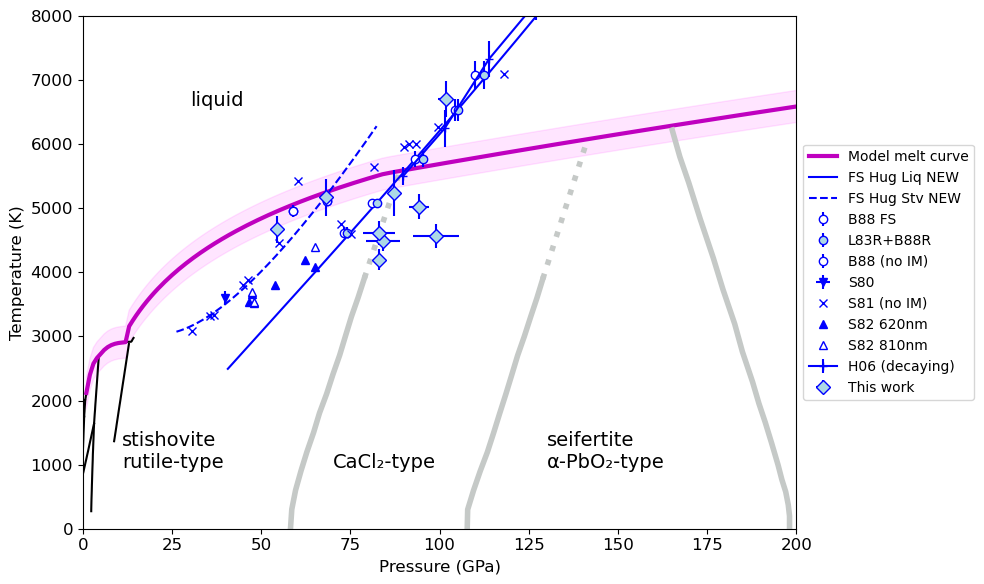

In [14]:
pind=9
%run -i scripts/PTphasediagram.py

In [15]:
print('CHECK THIS FS liquidus intersection:')
x,y=intersection(stsmcsmooth.P,stsmcsmooth.T,fs_hug_liq.P,fs_hug_liq.T)
print('P, T intersection point = ',x,y)
print('us = ',np.interp(x,fs_hug_liq.P,fs_hug_liq.us))
print('up = ',np.interp(x,fs_hug_liq.P,fs_hug_liq.up))
print('rho = ',np.interp(x,fs_hug_liq.P,fs_hug_liq.rho))

print('Compare to P, us = ',fs_startliq_P,fs_startliq_us)

CHECK THIS FS liquidus intersection:
P, T intersection point =  [90.51739] [5598.12759231]
us =  [8.78531049]
up =  [4.67480301]
rho =  [4.71056783]
Compare to P, us =  90.5101601196313 8.784993235759265


In [16]:
print('CHECK THIS FS Solidus intersection:')
ind = np.where(stsmcsmooth.P>30)[0]
x,y=intersection(stsmcsmooth.P[ind],stsmcsmooth.rho_s[ind],fs_hug_stv.P,fs_hug_stv.rho)
print('P, rho intersection point = ',x,y)
print('us = ',np.interp(x,fs_hug_stv.P,fs_hug_stv.us))
print('up = ',np.interp(x,fs_hug_stv.P,fs_hug_stv.up))
print('T = ',np.interp(x,fs_hug_stv.P,fs_hug_stv.T))

print('Compare to P, us = ',fs_startsol_P,fs_startsol_us)

CHECK THIS FS Solidus intersection:
P, rho intersection point =  [72.32639754] [4.73330942]
us =  [7.83653126]
up =  [4.18755941]
T =  [5500.95195274]
Compare to P, us =  72.32862722602232 7.836642933215169


9
0 Model liquidus Line2D(Model liquidus)
1 Model solidus Line2D(Model solidus)
2 T=300K Line2D(T=300K)
3 Temp. inversion <matplotlib.collections.FillBetweenPolyCollection object at 0x15c6a5950>
4 This work Line2D(This work)
5 New Hugoniot: Liquid region Line2D(New Hugoniot: Liquid region)
6 New Hugoniot: Solid region Line2D(New Hugoniot: Solid region)
7 PT liquidus intersection Line2D(PT liquidus intersection)
8   Line2D( )
9 W62 <ErrorbarContainer object of 3 artists>
10 J68 <ErrorbarContainer object of 3 artists>
11 L83R+B88R <ErrorbarContainer object of 3 artists>
12 T18 <ErrorbarContainer object of 3 artists>
13 R19 <ErrorbarContainer object of 3 artists>
14 O25 <ErrorbarContainer object of 3 artists>
15 B19 <ErrorbarContainer object of 3 artists>
16
Saved figure: B9-SiO2-P-rho-phase-diagram-FS-Fig8A.pdf


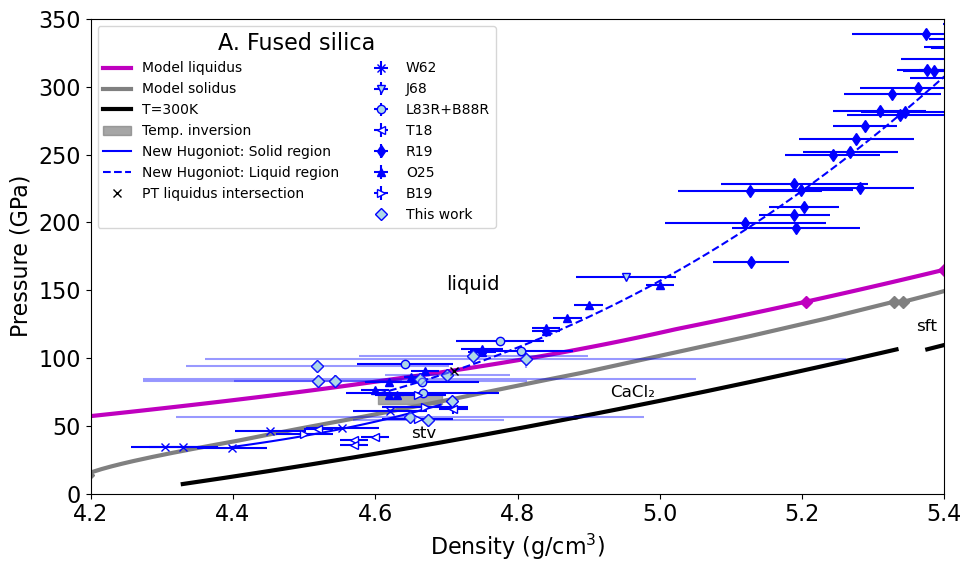

In [17]:
pind=9
%run -i scripts/PVphasediagram.py

In [18]:
## Check fused silica data

# shot 22
# Shock velocity is based on observed temperature

indA23fs = np.arange(0,9) # EOS points with error bars
print(shockdat_list[A23fs['id']].exp_id[2])
print(shockdat_list[A23fs['id']].T[2],shockdat_list[A23fs['id']].T_std[2])
T = shockdat_list[A23fs['id']].T[2]
dT = shockdat_list[A23fs['id']].T_std[2]
print(shockdat_list[A23fs['id']].P[2])
#dT = shockdat_list[A23fs['id']].T_std[2]

Us = np.interp(T,fs_hug_liq.T,fs_hug_liq.us)
Ush= np.interp(T,fs_hug_liq.T+dT,fs_hug_liq.us)
Usl=np.interp(T,fs_hug_liq.T-dT,fs_hug_liq.us)

print(Us,Ush,Usl,Ush-Us,Usl-Us)
print(np.mean([abs(Ush-Us),abs(Usl-Us)]))

shot22
4573.230527 186.3923
99.09285426949843
8.036637340453682 7.889898997768358 8.17986947766479 -0.1467383426853237 0.1432321372111076
0.14498523994821566


In [19]:
## Shot 022
#No impact velocity measured.
#Constrained by transit time of NIR.

us = 9163.4 # shock velocity m/s
samplethick=0.002945 # m
dtt = samplethick/us*1.e6
us = 8800 # shock velocity m/s
samplethick=0.002945 # m
dtt2 = samplethick/us*1.e6
us = 9300 # shock velocity m/s
samplethick=0.002945 # m
dtt3 = samplethick/us*1.e6

us1 = 9163.4 # shock velocity m/s
us2 = 8800 # shock velocity m/s
us3 = 9300 # shock velocity m/s


p1=np.interp(us1/1.e3,fs_hug_liq.us,fs_hug_liq.P)
p2=np.interp(us2/1.e3,fs_hug_liq.us,fs_hug_liq.P)
p3=np.interp(us3/1.e3,fs_hug_liq.us,fs_hug_liq.P)
print(p1,p2,p3)

print(p1-p2)
print(us1-us2)

99.34827252959596 90.85249184086801 102.64440923482611
8.495780688727947
363.39999999999964


In [20]:
print(shockdat[iJ68fs.i].refidlist)

[0, 306]


In [21]:
print(ref_list[306].bibtex)

['@report{Jones1968,   address={Warren, Michigan},    type={Interim Report  Contract NAS2-3427},   title={Material Properties Measurements for Selected Materials},   number={NASA NTRS 68N28631},    institution={General Motors Technical Center},   author={Jones, A. H. and Isbell, W. M. and Shipman, F. H. and Perkins, R. D. and Green, S. J. and Maiden, C. J.},  year={1968},   month=apr,    pages={56} }']


In [22]:
x,y = intersection(fs_hug_stv.P,fs_hug_stv.rho,stsmcsmooth.P,stsmcsmooth.rho_s)
print('cross solidus = ',x,y)

cross solidus =  [27.64421059 72.32639754] [4.292826   4.73330942]


## Check consistency between EOS and Hugoniot Fits

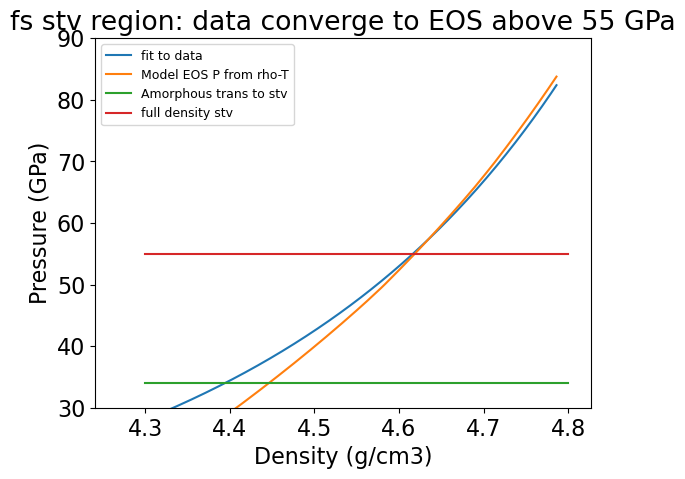

In [23]:
# check T(P,rho) model vs. data

pmodel=[]
for iii in range(len(fs_hug_stv.T)):
    stvpvt.isotherm_stv(fs_hug_stv.T[iii])
    pmodel.append(np.interp(fs_hug_stv.rho[iii],stvpvt.rhoarr,stvpvt.isotherm_p))


plt.plot(fs_hug_stv.rho,fs_hug_stv.P,label='fit to data')
plt.plot(fs_hug_stv.rho,pmodel,label='Model EOS P from rho-T')
plt.title('fs stv region: data converge to EOS above 55 GPa')
plt.plot([4.3,4.8],[fs_trans_stv_P,fs_trans_stv_P],label='Amorphous trans to stv')
plt.plot([4.3,4.8],[55,55],label='full density stv')
plt.legend(fontsize=lfss)
plt.ylim(30,90)
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.savefig(outputfigpath+'fs-stv-test.pdf')
plt.show()


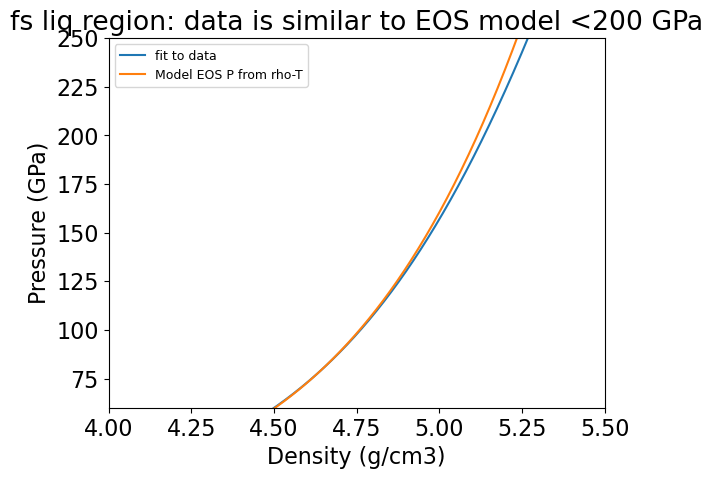

In [24]:
# check T(P,rho) model vs. data
# liquid already confirmed in dft-offset.ipynb

pmodel=[]
for iii in range(len(fs_hug_liq.T)):
    karkipvt.isotherm_liquid(fs_hug_liq.T[iii])
    pmodel.append(np.interp(fs_hug_liq.rho[iii],karkipvt.rhoarr,karkipvt.isotherm_p))


plt.plot(fs_hug_liq.rho,fs_hug_liq.P,label='fit to data')
plt.plot(fs_hug_liq.rho,pmodel,label='Model EOS P from rho-T')
plt.title('fs liq region: data is similar to EOS model <200 GPa')
plt.legend(fontsize=lfss)
plt.ylim(60,250)
plt.xlim(4,5.5)
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.savefig(outputfigpath+'fs-liq-test.pdf')
plt.show()


## Calculate Monte Carlo Uncertainty Envelopes

In [ ]:
import time


## Fused silica PVT Hugoniot
print('Fused silia PTV Hugoniot Monte-Carlo uncertainties')
nsteps = [500,1000]
nupind = 500
print('number of up points = ',nupind)
mc_list =  []
for ii in range(len(nsteps)):
    start_time = time.perf_counter()

    dat_mc = hpmc.HPeos_MC()
    dat_mc.npts = nsteps[ii]
    
    dat_mc.up_ind = np.linspace(fs_fit_liq0.xrange[0],fs_fit_liq0.xrange[1],nupind)
    dat_mc.calcMC(fs_fit_liq0 ,fs_fitTus_liq0,verbose=False)

    end_time = time.perf_counter()
    print('Time: ',nsteps[ii],end_time - start_time)

    mc_list.append(deepcopy(dat_mc))
    

In [ ]:
#%run -i set_plotstyle.py # customize matplotlib
#%run -i set_colors.py # custom colors
plt.rcParams.update(plt.rcParamsDefault)
fig, ax = plt.subplots(4, 1,figsize=fsize5)
plt.rcParams['lines.markersize'] = mks
plt.rcParams.update({'font.size': 8})

maxp=0
maxr=0
maxt=0
mint=10000
maxus=0

minup = min(mc_list[0].up_ind)
maxup = max(mc_list[0].up_ind)
for ii in range(len(mc_list)):

    xi=0
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].us_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].us_std)>maxus:
        maxus=max(mc_list[ii].us_std)
        
    xi=1
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].p_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].p_std)>maxp:
        maxp=max(mc_list[ii].p_std)
    xi=2
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].rho_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].rho_std)>maxr:
        maxr=max(mc_list[ii].rho_std)    
    xi=3
    ax[xi].plot(mc_list[ii].up_ind,mc_list[ii].t_std,label='NMC = '+str(mc_list[ii].npts))
    if max(mc_list[ii].t_std)>maxt:
        maxt=max(mc_list[ii].t_std)       
    if min(mc_list[ii].t_std)<mint:
        mint=min(mc_list[ii].t_std)       

xi=0
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxus)
ax[xi].set_ylabel('Shock Velocity (km/s)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].set_title('Fused Silica Hugoniot Monte Carlo uncertainties')


xi=1
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxp)
ax[xi].set_ylabel('Pressure Sigma (GPa)')
ax[xi].set_xlabel('Particle Velocity (km/s)')
ax[xi].legend(fontsize=lfss)

xi=2
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(0,maxr)
ax[xi].set_ylabel('Density Sigma (g/cm³)')
ax[xi].set_xlabel('Particle Velocity (km/s)')


xi=3
ax[xi].set_xlim(minup,maxup)
ax[xi].set_ylim(mint,maxt)
ax[xi].set_yscale('log')
ax[xi].set_ylabel('Temperature Sigma (K)')
ax[xi].set_xlabel('Particle Velocity (km/s)')



fig.tight_layout()
plt.savefig(outputfigpath+tag+'mc-sensitivity.pdf')
plt.show()
plt.rcParams.update(plt.rcParamsDefault)